# PCA on preprocessed data


    Imports

In [1]:
import os
import random

import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
import time

In [2]:
SEED = 0          # même graine que 1-Prepocessing : découpage identique
D = 64            # dimension de représentation, IDENTIQUE pour la PCA et l'AE
TEST_SIZE = 0.2   # part de cellules en validation
BATCH_SIZE = 128

In [3]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

pd.set_option("display.width", 200)

repertoire = os.getcwd()
DATA_DIR = os.path.dirname(repertoire)

Data loading

In [4]:
train = sc.read_h5ad(f"{repertoire}/data/train.h5ad")
val = sc.read_h5ad(f"{repertoire}/data/val.h5ad")

Xt = train.X
Xv = val.X

if sp.issparse(Xt):
    X_train = Xt.toarray()
else:
    X_train = Xt
X_train = np.asarray(X_train, dtype = np.float32)

if sp.issparse(Xv):
    X_val = Xv.toarray()
else:
    X_val = Xv
X_val = np.asarray(X_val, dtype = np.float32)

print(X_train)
print(X_train.shape)
print(X_val.shape)

[[0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         1.441046  ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 ...
 [0.07017838 0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.39168957 ... 0.         0.         0.39168957]]
(13105, 3000)
(3277, 3000)


PCA

In [5]:
pca = PCA(n_components=D, random_state=SEED)

Z_pca_train = pca.fit_transform(X_train)
Z_pca_val = pca.transform(X_val)

X_pca_train = pca.inverse_transform(Z_pca_train)
X_pca_val = pca.inverse_transform(Z_pca_val)

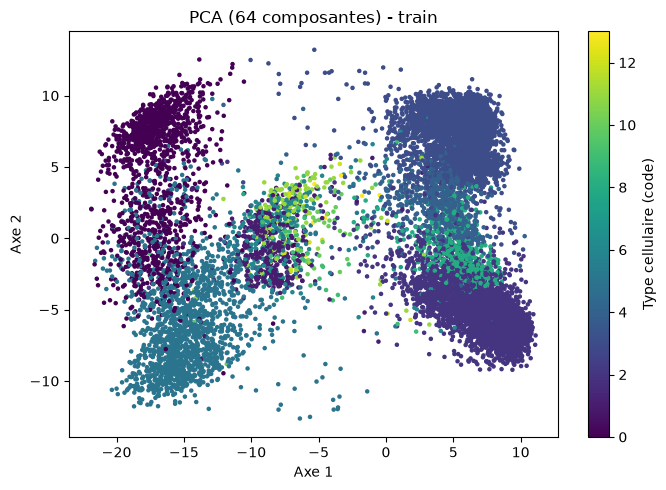

In [6]:
# Récupération des labels cellulaires
labels = train.obs["celltype"].astype("category")
codes = labels.cat.codes.to_numpy()


# Réduction des 50 dimensions en 2 dimensions pour la visualisation
Z_pca_2d = PCA(n_components=2, random_state=SEED).fit_transform(Z_pca_train)

# Visualisation
plt.figure(figsize=(7, 5))

im = plt.scatter(
    Z_pca_2d[:, 0],
    Z_pca_2d[:, 1],
    c=codes,
    cmap="viridis",
    s=5
)

plt.title(f"PCA ({D} composantes) - train")
plt.xlabel("Axe 1")
plt.ylabel("Axe 2")

plt.colorbar(im, label="Type cellulaire (code)")

plt.tight_layout()
plt.show()

PCA Visualsation

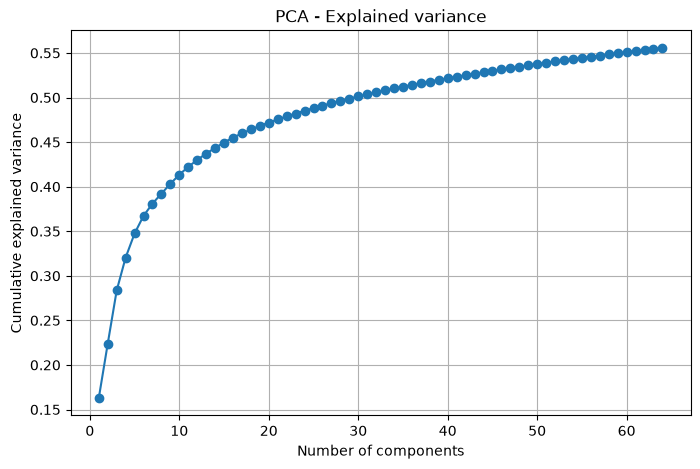

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 65),
    np.cumsum(pca.explained_variance_ratio_),
    marker="o"
)

plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA - Explained variance")
plt.grid()
plt.show()

Data reconstruction

In [9]:
# Reconstruction des données à partir de la PCA
X_reconstructed = pca.inverse_transform(Z_pca_train)

# Reprojection des données reconstruites dans l'espace PCA
Reconstructed_pca = pca.transform(X_reconstructed)

Reconstructed data visualisation

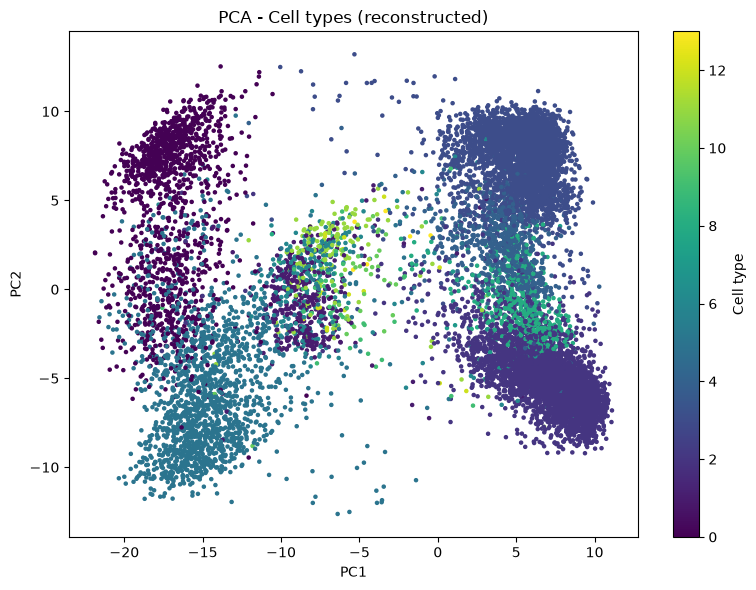

In [10]:
plt.figure(figsize=(8, 6))

plt.scatter(
    Reconstructed_pca[:, 0],
    Reconstructed_pca[:, 1],
    c=train.obs["celltype"].astype("category").cat.codes.to_numpy(),
    cmap="viridis",
    s=5
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA - Cell types (reconstructed)")
plt.colorbar(label="Cell type")
plt.tight_layout()
plt.show()

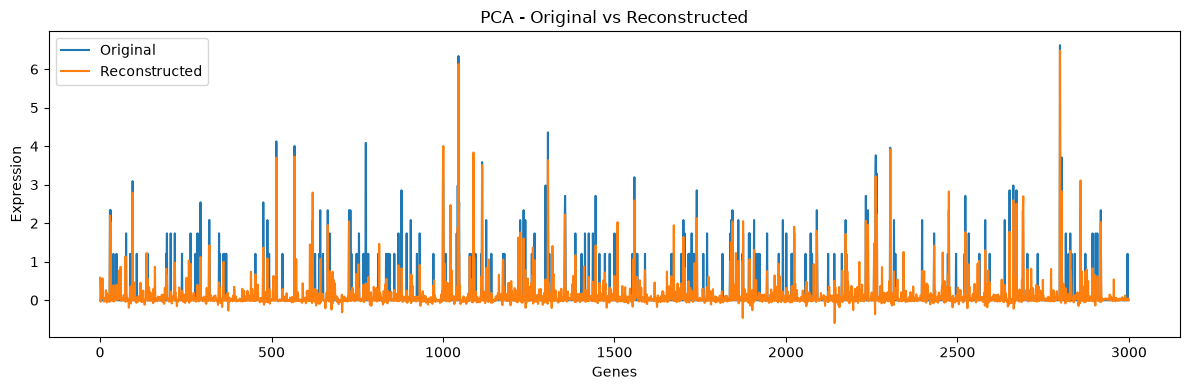

In [11]:
plt.figure(figsize=(12, 4))

plt.plot(X_train[0], label="Original")
plt.plot(X_reconstructed[0], label="Reconstructed")

plt.legend()
plt.xlabel("Genes")
plt.ylabel("Expression")
plt.title("PCA - Original vs Reconstructed")

plt.tight_layout()
plt.show()

### Erreur de reconstruction (MSE)

La qualité de reconstruction des données après réduction dimensionnelle par PCA est évaluée à l'aide de l'erreur quadratique moyenne (*Mean Squared Error*, MSE).

Elle est calculée séparément sur les jeux d'entraînement (*train*) et de validation (*validation*).


In [12]:
mse_pca_train = mean_squared_error(X_train, X_reconstructed)
mse_pca_val = mean_squared_error(X_val, X_pca_val)

In [13]:
import os
import numpy as np

# Créer un dossier pour les résultats s'il n'existe pas
os.makedirs("results", exist_ok=True)

# Sauvegarder les résultats de la PCA
np.savez_compressed(
    "results/resultats_PCA.npz",

    # Représentations latentes
    Z_train=Z_pca_train,
    Z_val=Z_pca_val,

    # Données reconstruites
    X_reconstructed_train=X_reconstructed,
    X_reconstructed_val=X_pca_val,

    # Métriques
    mse_train=mse_pca_train,
    mse_val=mse_pca_val,

    variance_expliquee=pca.explained_variance_ratio_.sum(),

    # Identification des cellules
    train_obs_names=train.obs_names.to_numpy(),
    val_obs_names=val.obs_names.to_numpy()
)

print("Résultats PCA sauvegardés.")

Résultats PCA sauvegardés.
